## Exercise 1
### a) Consider the first two classes of the Cork Stoppers.xls data set, and the features ART and PRT. Fit a Bayes classifier, compute the decision boundary and the training error.

In [ ]:
import pandas as  pd
import numpy as np
from sklearn.model_selection import train_test_split
import plotly.express as px
import plotly.graph_objects as go
from function import Classifier ## Custom made class of classifiers

df = pd.read_excel('D:/UC_library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/CORK_STOPPERS.XLS', sheet_name='Data', usecols=['ART', 'PRT', 'C'])
df = df.dropna()
ind_1 = np.where(df['C'] == 1)
ind_2 = np.where(df['C'] == 2)
ind = np.concat(ind_1 + ind_2)

df = df.to_numpy()
df = df[ind , :]
x = df[:, [1, 2]]
y = df[:,0]

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.15, random_state=1
)

# Normalise data
# x_norm = (x - np.mean(x_train, axis=0)) / np.std(x, axis=0)
x_norm = x

#----------------------------------------------------------------------------
x_test = (x_test - np.mean(x_train, axis=0)) / np.std(x_train, axis = 0)

# Prevalence
Pw1 = len(y[y == 1]) / len(y)
Pw2 = len(y[y == 2]) / len(y)

# Means
mu1 = np.mean(x_norm[y == 1],axis=0)
mu2 = np.mean(x_norm[y == 2],axis=0)
# Variance
c_1 = np.cov(x_norm[y == 1], rowvar=False)
c_2 = np.cov(x_norm[y == 2], rowvar = False)

C_inv = np.linalg.inv((c_1 + c_2) / 2)
print(C_inv)

prediction = list()


for i in range(len(x_norm)):
    # px1 = Pw1*gaussian_pdf(x[i,:], mu1, v1)
    # px2 = Pw2*gaussian_pdf(x[i,:], mu2, var2) 
    
    g1 =  -0.5 * (x_norm[i,:] - mu1).T @ C_inv @(x_norm[i,:] - mu1) + np.log(Pw1)
    g2 =  -0.5 * (x_norm[i,:] - mu2).T @ C_inv @(x_norm[i,:] - mu2) + np.log(Pw2)
    Px = max(g1, g2)
    if(Px==g1):
        prediction.append(1)
    else: prediction.append(2)
#-------------------------------------------------------------------------------------
print('g2: ' , g2)
## OR ##

#----------
# ### USE CUSTOM CLASSIFIER ###
# model = Classifier(x_norm, y, x_norm)
# prediction = model.Naive_Bayes()
#-----------
    
TP = np.sum((prediction == y) & (y == 1))
TN = np.sum((prediction == y) & (y == 2))
FP = np.sum((prediction != y) & (y == 1))
FN = np.sum((prediction != y) & (y == 2))

Precision = (TP / (TP + FP)) * 100
Sensitivity = (TP / (TP + FN)) * 100
Specificity = (TN / (TN + FP)) * 100
f1score = 2 * ((Precision * Sensitivity) / (Precision + Sensitivity))

print(f'Bayesian Classifiction model on CorkStoppers:\nPrecision: {Precision}%\nSensitivity: {Sensitivity}%\nSpecificity: {Specificity}%\nF1Score: {f1score}%')

## Decision function

w = C_inv @ (mu1 - mu2)
w0 = 0.5*(mu1.T @ C_inv @ mu1 - mu2.T @ C_inv @ mu2) + np.log(Pw1 / Pw2)

dx = np.arange(50,400,1)
dy = (-w[0]*dx)/w[1] - w0/w[1]

fig = px.scatter(x = x_norm[:, 0], y = x_norm[:, 1], color=y.astype(str))
fig.add_trace(go.Scatter(x = dx, y = dy, mode='lines'))

fig.show()




[[ 0.00275693 -0.00113881]
 [-0.00113881  0.00052836]]
g2:  -1.6180015384105442
Bayesian Classifiction model on CorkStoppers:
Precision: 96.0%
Sensitivity: 85.71428571428571%
Specificity: 95.45454545454545%
F1Score: 90.56603773584904%
[-0.05417134  0.00627715]


### b) Consider the three most discriminative features, acourding to KruskalWallis, of the Cork Stoppers.xls data set. Compute the Bayes error for the three classes problem.


In [19]:
import pandas as  pd
import numpy as np
from function import Classifier, metrics
from scipy import stats
folder = "D:/UC_library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets/"

df = pd.read_excel(folder + "CORK_STOPPERS.XLS", sheet_name="Data")
df = df.dropna()

features = ["ART", "N.1", "PRT", "ARM", "PRM", "ARTG", "NG", "PRTG", "RAAR", "RAN"]
H = {feature : None for feature in features}

# kruskal wallis test 
for i in features:
    Super = df.loc[df["C"] == 1, i].values
    Average = df.loc[df["C"] == 2, i].values
    Poor = df.loc[df["C"] == 3, i].values

    H[i] =  stats.kruskal(Super, Average, Poor).statistic
   
sort_H = sorted(H.items(), key= lambda x:x[1], reverse=True)

for key,value in sort_H:
    print(key , ':' , value)


ART : 121.58964258474009
PRM : 117.63782046335828
PRT : 115.74851860346449
ARTG : 115.21685092055695
ARM : 113.53079541575394
PRTG : 113.33179317347778
RAAR : 105.18901177731905
NG : 104.41349241044973
RAN : 94.28568910767306
N.1 : 74.49926324214721


### 3 most relevant features according to kruskal-wallis:
 - ART
 - PRM
 - PRT

[[ 81.     6.1  250.  ]
 [ 80.     5.67 238.  ]
 [ 81.     7.54 196.  ]
 [125.     5.84 368.  ]
 [146.     7.78 350.  ]
 [109.     5.75 316.  ]
 [161.     7.02 400.  ]
 [136.     6.09 402.  ]
 [156.     6.63 424.  ]
 [ 95.     6.68 254.  ]
 [163.     8.75 350.  ]
 [112.     5.89 318.  ]
 [130.     6.33 348.  ]
 [134.     6.7  362.  ]
 [167.     7.25 428.  ]
 [159.     6.11 452.  ]
 [195.     7.43 468.  ]
 [176.     6.91 484.  ]
 [141.     6.54 366.  ]
 [146.     8.63 238.  ]
 [142.     6.54 328.  ]
 [155.     6.85 418.  ]
 [200.     6.33 576.  ]
 [114.     5.67 346.  ]
 [178.     7.   462.  ]
 [ 92.     5.84 292.  ]
 [165.     6.83 430.  ]
 [145.     6.86 350.  ]
 [ 63.     7.08 170.  ]
 [139.     6.41 410.  ]
 [139.     6.41 410.  ]
 [119.     6.45 342.  ]
 [107.     6.28 270.  ]
 [241.     7.62 602.  ]
 [143.     7.55 332.  ]
 [205.     6.79 536.  ]
 [144.     6.76 392.  ]
 [136.     5.77 392.  ]
 [ 35.     5.78 104.  ]
 [153.     6.78 434.  ]
 [135.     6.61 390.  ]
 [ 88.     6.15 

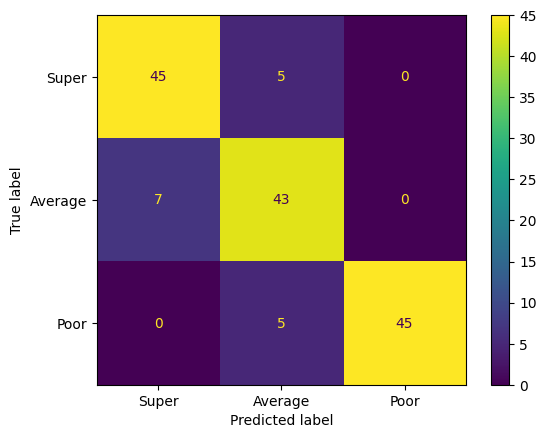

In [ ]:
data = pd.DataFrame(df, columns=['ART', 'PRM', 'PRT', 'C'])

data = data.to_numpy()

x = data[:,[0,1,2]]
y = data[:, 3]


model = Classifier(x,y,x)
predictions = model.Naive_Bayes()

metrics(y, predictions, ['Super','Average','Poor'])



## Exercise 2
### Consider the Ripley data in files riply trn.mat and riply tst.mat. The files contain labeled points corresponding to two classes. Build a Bayesian classifier using riply trn.mat by considering the likelihoods as Gaussian PDFs. Test the classifier with the Ripley data test set: riply tst.mat. Compute also the decision boundary

(250, 2) (250,)
Accuracy: 89.2%
              precision    recall  f1-score   support

           1       0.89      0.90      0.89       500
           2       0.90      0.88      0.89       500

    accuracy                           0.89      1000
   macro avg       0.89      0.89      0.89      1000
weighted avg       0.89      0.89      0.89      1000



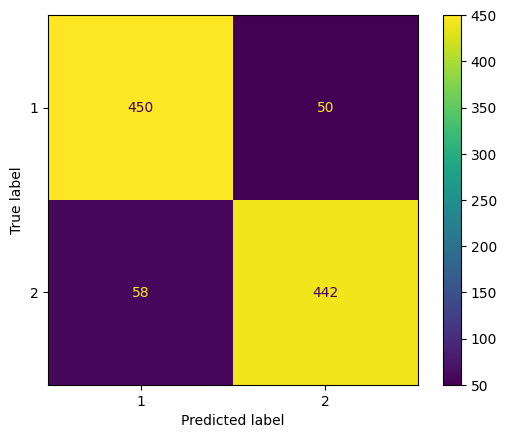

In [39]:
import scipy.io as sio
import numpy as np
from function import Classifier, metrics

datasets_folder = 'D:/UC_library/Mestrado/1_ANO/2_semestre/RP/PL/data_sets'

data1 = sio.loadmat(datasets_folder + "/riply_trn.mat")
data2 = sio.loadmat(datasets_folder + "/riply_tst.mat")

x1 = data1['X'][:,:].T
y1 = data1['y'][:,:].T
y1 = y1.flatten()

print(np.shape(x1), np.shape(y1))

x2 = data2['X'][:,:].T
y2 = data2['y'][:,:].T
y2 = y2.flatten()

model = Classifier(x1, y1, x2)
prediction = model.Naive_Bayes()
# prediction = model.Mahalanobis()
metrics(y2, prediction, ['1', '2'])

